# Задание 2.10*

Изобразите на сфере Римана логарифмическую спираль, заданную уравнением

$$
r=ae^{b\varphi}.
$$

## Теория

**Логарифмическая спираль.** В комплексной записи $z(\varphi)=re^{i\varphi}=a\,e^{(b+i)\varphi}$, $\varphi\in(-\infty,+\infty)$. При $\varphi\to-\infty$ спираль наматывается на точку $z=0$, при $\varphi\to+\infty$ уходит в бесконечность. Её главное свойство: она пересекает все лучи, выходящие из нуля, под **одним и тем же углом** $\alpha$:

$$
\operatorname{tg}\alpha=\frac{r}{dr/d\varphi}=\frac1b .
$$

**Стереографическая проекция** на сферу Римана $\xi^2+\eta^2+\left(\zeta-\frac12\right)^2=\frac14$ (см. задание 2.10):

$$
\xi=\frac{r\cos\varphi}{1+r^2},\qquad \eta=\frac{r\sin\varphi}{1+r^2},\qquad \zeta=\frac{r^2}{1+r^2},\qquad r=ae^{b\varphi}.
$$

Она обладает двумя свойствами:

- лучи $\arg z=const$ переходят в **меридианы** сферы, окружности $|z|=const$ — в **параллели** (окружность $|z|=1$ — в экватор);
- проекция **конформна**, то есть сохраняет углы между кривыми.

Следовательно, образ спирали пересекает все меридианы под тем же постоянным углом $\alpha=\operatorname{arctg}\frac1b$. Такая кривая на сфере называется **локсодромой** (линия постоянного курса в навигации). Она делает бесконечно много витков вокруг обоих полюсов: южного $S$ (образ точки $0$) и северного $N$ (образ $\infty$), но имеет конечную длину $\dfrac{\pi}{2\cos\alpha}=\dfrac{\pi\sqrt{1+b^2}}{2b}$ (длина меридиана $\frac\pi2$, делённая на $\cos\alpha$).

**В коде:** строим спираль на плоскости и её образ на сфере, а затем численно проверяем оба утверждения — постоянство угла с меридианами и формулу длины.

Угол с меридианами: от 78.6901° до 78.6901°;  arctg(1/b) = 78.6901°
Длина образа спирали: 8.00949;  π·sqrt(1 + b²)/(2b) = 8.00952


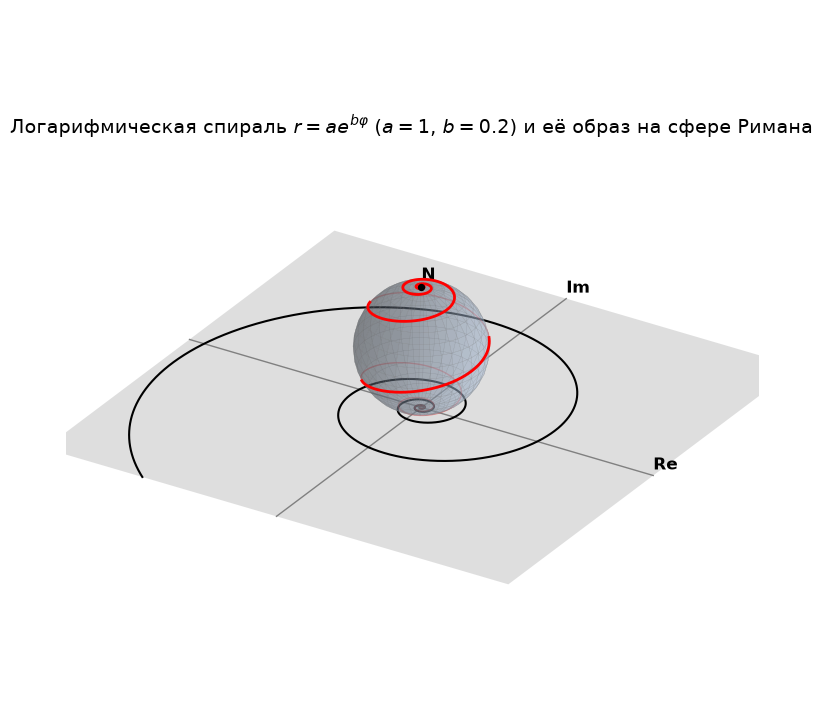

In [1]:
import numpy as np
import matplotlib.pyplot as plt

a, b = 1.0, 0.2                 # параметры спирали r = a·e^{bφ}
L = 2.0                         # на плоскости рисуем квадрат [-L, L] × [-L, L]

# Спираль на плоскости: φ от -20π до 20π (r меняется от ~3e-6 до ~3e5)
phi = np.linspace(-20*np.pi, 20*np.pi, 200001)
r = a*np.exp(b*phi)
x, y = r*np.cos(phi), r*np.sin(phi)

# Стереографическая проекция на сферу ξ² + η² + (ζ - 1/2)² = 1/4
d = 1 + r**2
xi, eta, zeta = x/d, y/d, r**2/d

# ---------- Проверка 1: угол между спиралью на сфере и меридианами постоянен ----------
T = np.gradient(np.column_stack([xi, eta, zeta]), phi, axis=0)          # касательный вектор кривой
M = np.column_stack([np.cos(phi)*(1 - r**2)/d**2,                       # касательная к меридиану:
                     np.sin(phi)*(1 - r**2)/d**2,                       # производная по r при φ = const
                     2*r/d**2])
cos_angle = np.sum(T*M, axis=1)/(np.linalg.norm(T, axis=1)*np.linalg.norm(M, axis=1))
angle = np.degrees(np.arccos(cos_angle[1:-1]))
print(f"Угол с меридианами: от {angle.min():.4f}° до {angle.max():.4f}°;  arctg(1/b) = {np.degrees(np.arctan(1/b)):.4f}°")

# ---------- Проверка 2: длина локсодромы ----------
length = np.sum(np.linalg.norm(np.diff(np.column_stack([xi, eta, zeta]), axis=0), axis=1))
print(f"Длина образа спирали: {length:.5f};  π·sqrt(1 + b²)/(2b) = {np.pi*np.sqrt(1 + b**2)/(2*b):.5f}")

# ---------- Рисунок ----------
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(projection='3d')
ax.computed_zorder = False                  # порядок рисования задаём сами через zorder
ax.view_init(elev=28, azim=-58)
ax.set_proj_type('ortho')

# Плоскость с осями Re, Im
PX, PY = np.meshgrid([-L, L], [-L, L])
ax.plot_surface(PX, PY, 0*PX, color='lightgray', alpha=0.35, zorder=0)
ax.plot([-L, L], [0, 0], [0, 0], color='gray', lw=1, zorder=1)
ax.plot([0, 0], [-L, L], [0, 0], color='gray', lw=1, zorder=1)
ax.text(L, 0, 0.05, "Re", fontsize=12, weight='bold')
ax.text(0, L, 0.05, "Im", fontsize=12, weight='bold')

# Спираль на плоскости (часть, попавшая в квадрат)
inside = (np.abs(x) <= L) & (np.abs(y) <= L)
ax.plot(np.where(inside, x, np.nan), np.where(inside, y, np.nan), 0*x, color='k', lw=1.5, zorder=2)

# Сфера Римана: центр (0, 0, 1/2), радиус 1/2
u, v = np.meshgrid(np.linspace(0, 2*np.pi, 37), np.linspace(0, np.pi, 19))
ax.plot_surface(0.5*np.cos(u)*np.sin(v), 0.5*np.sin(u)*np.sin(v), 0.5 + 0.5*np.cos(v),
                color='lightsteelblue', alpha=0.35, edgecolor='gray', linewidth=0.2, zorder=3)

# Образ спирали (локсодрома): ближнюю к наблюдателю часть рисуем жирно, дальнюю — бледно
el, az = np.radians(ax.elev), np.radians(ax.azim)
cam = np.array([np.cos(el)*np.cos(az), np.cos(el)*np.sin(az), np.sin(el)])     # направление на наблюдателя
front = xi*cam[0] + eta*cam[1] + (zeta - 0.5)*cam[2] >= 0
for mask, style in ((~front, dict(lw=1, alpha=0.35, zorder=2)), (front, dict(lw=2, zorder=5))):
    ax.plot(np.where(mask, xi, np.nan), np.where(mask, eta, np.nan), np.where(mask, zeta, np.nan),
            color='red', **style)

ax.scatter([0], [0], [1], color='k', s=18, zorder=7)
ax.text(0, 0, 1.06, "N", fontsize=12, weight='bold')

ax.set_xlim(-L, L)
ax.set_ylim(-L, L)
ax.set_zlim(0, 1)
ax.set_box_aspect((2*L, 2*L, 1), zoom=1.1)      # одинаковый масштаб по всем осям
ax.set_axis_off()
ax.set_title(rf"Логарифмическая спираль $r = a e^{{b\varphi}}$ ($a = {a:g}$, $b = {b:g}$) и её образ на сфере Римана",
             fontsize=14, y=0.88)
plt.show()